# Rural/Urban Classification

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df0= pd.read_excel("Rural_Urban_Classification_(2021)_of_LSOAs.xlsx")
df0 = df0.rename(columns={"LSOA21CD": "LSOA_code"})
df0.head()

,LSOA_code,LSOA21NM,RUC21CD,RUC21NM,Urban_rural_flag
0,E01000001,City of London 001A,UN1,Urban: Nearer to a major town or city,Urban
1,E01000002,City of London 001B,UN1,Urban: Nearer to a major town or city,Urban
2,E01000003,City of London 001C,UN1,Urban: Nearer to a major town or city,Urban
3,E01000005,City of London 001E,UN1,Urban: Nearer to a major town or city,Urban
4,E01000006,Barking and Dagenham 016A,UN1,Urban: Nearer to a major town or city,Urban


Each LSOA region is classified as either urban or rural

# Data Cleaning

In [7]:
#Remove the rows for Wales
df = df0[~df0["LSOA_code"].str.startswith("W")]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33755 entries, 0 to 33963
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   LSOA_code         33755 non-null  object
 1   LSOA21NM          33755 non-null  object
 2   RUC21CD           33755 non-null  object
 3   RUC21NM           33755 non-null  object
 4   Urban_rural_flag  33755 non-null  object
dtypes: object(5)
memory usage: 1.5+ MB


In [9]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate LSOA codes:", df["LSOA_code"].duplicated().sum())

LSOA_code           0
LSOA21NM            0
RUC21CD             0
RUC21NM             0
Urban_rural_flag    0
dtype: int64
Duplicate rows: 0
Duplicate LSOA codes: 0


# EDA

In [10]:
#Urban to Rural distribution
print(df["Urban_rural_flag"].value_counts())

print(
    df["Urban_rural_flag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Urban_rural_flag
Urban    28201
Rural     5554
Name: count, dtype: int64
Urban_rural_flag
Urban    83.55
Rural    16.45
Name: proportion, dtype: float64


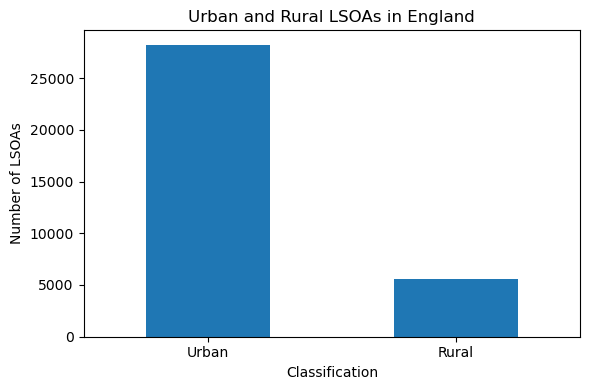

In [11]:
df["Urban_rural_flag"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Urban and Rural LSOAs in England")
plt.xlabel("Classification")
plt.ylabel("Number of LSOAs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

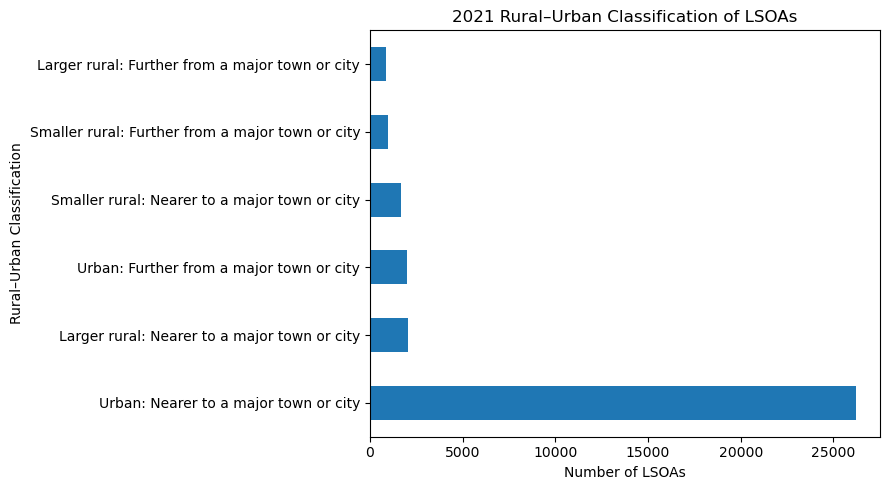

In [13]:
# A detailed outlook of rural urban scenario
df["RUC21NM"].value_counts().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("2021 Rural–Urban Classification of LSOAs")
plt.xlabel("Number of LSOAs")
plt.ylabel("Rural–Urban Classification")
plt.tight_layout()
plt.show()

From the above two graphs, we can infer that most LSOAs(regions) are classified as Urban, consisting of more than 25000 compared to Rural which amounts to around 6000 

# Feature Engineering

In [16]:
df["rural_flag"] = (df["Urban_rural_flag"] == "Rural").astype(int)

print(
    df[["Urban_rural_flag", "rural_flag"]]
    .drop_duplicates()
)

     Urban_rural_flag  rural_flag
0               Urban           0
4559            Rural           1


C:\Users\ANSHAD JALEEL\AppData\Local\Temp\ipykernel_31992\3150436908.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["rural_flag"] = (df["Urban_rural_flag"] == "Rural").astype(int)


rural_flag
0    28201
1     5554
Name: count, dtype: int64
                  count  mean
Urban_rural_flag             
Rural              5554   1.0
Urban             28201   0.0


In [20]:
rural_urban_features = df[
    [
        "LSOA_code",
        "RUC21CD",
        "RUC21NM",
        "Urban_rural_flag",
        "rural_flag"
    ]
].copy()

print(rural_urban_features.head())
print(rural_urban_features.shape)

   LSOA_code RUC21CD                                RUC21NM Urban_rural_flag  \
0  E01000001     UN1  Urban: Nearer to a major town or city            Urban   
1  E01000002     UN1  Urban: Nearer to a major town or city            Urban   
2  E01000003     UN1  Urban: Nearer to a major town or city            Urban   
3  E01000005     UN1  Urban: Nearer to a major town or city            Urban   
4  E01000006     UN1  Urban: Nearer to a major town or city            Urban   

   rural_flag  
0           0  
1           0  
2           0  
3           0  
4           0  
(33755, 5)


Cleaned and Transformed the dataset and following features were selected which was then saved into a new dataset as shown below.

In [21]:
rural_urban_features.to_excel(
    "rural_urban_features.xlsx",
    index=False
)

The saved dataset will used be used in master notebook to form an integrated dataset.